In [ ]:
%%capture

#installation libraries
!pip install pafy youtube-dl moviepy

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import cv2
import random
import numpy as np

# Constants
SEQUENCE_LENGTH = 20  # Number of frames per video sequence
IMAGE_HEIGHT, IMAGE_WIDTH = 128, 128  # Frame dimensions
DATASET_DIR = "/content/drive/MyDrive/UCF5"  # Correct dataset path

# Dynamically generate class list from dataset directory
CLASSES_LIST = [folder for folder in os.listdir(DATASET_DIR) if os.path.isdir(os.path.join(DATASET_DIR, folder))]

print("Classes found in the dataset:")
for class_name in CLASSES_LIST:
    print(class_name)

def frames_extraction(video_path):
    """
    Extract a fixed number of frames (SEQUENCE_LENGTH) from a video.
    """
    frames_list = []
    video_reader = cv2.VideoCapture(video_path)
    video_frames_count = 0

    # Count frames manually if CAP_PROP_FRAMES_COUNT isn't available
    while True:
        success, _ = video_reader.read()
        if not success:
            break
        video_frames_count += 1

    video_reader.release()

    # Reopen video for frame extraction
    video_reader = cv2.VideoCapture(video_path)
    skip_frames_window = max(int(video_frames_count / SEQUENCE_LENGTH), 1)

    for frame_counter in range(SEQUENCE_LENGTH):
        video_reader.set(cv2.CAP_PROP_POS_FRAMES, frame_counter * skip_frames_window)
        success, frame = video_reader.read()
        if not success:
            break

        resized_frame = cv2.resize(frame, (IMAGE_HEIGHT, IMAGE_WIDTH))
        normalized_frame = resized_frame / 255.0
        frames_list.append(normalized_frame)

    video_reader.release()
    return frames_list

def create_dataset():
    """
    Create the dataset by extracting frames from all video files in the dataset directory.
    """
    features = []
    labels = []
    video_file_paths = []

    for class_index, class_name in enumerate(CLASSES_LIST):
        print(f"Extracting data for class: {class_name}")
        class_dir = os.path.join(DATASET_DIR, class_name)

        # Traverse all subdirectories and collect video file paths
        for root, _, files in os.walk(class_dir):
            for file_name in files:
                if file_name.endswith(('.avi', '.mp4', '.mkv')):  # Adjust extensions as needed
                    video_file_path = os.path.join(root, file_name)
                    frames = frames_extraction(video_file_path)
                    if len(frames) == SEQUENCE_LENGTH:
                        features.append(frames)
                        labels.append(class_index)
                        video_file_paths.append(video_file_path)

    features = np.asarray(features)
    labels = np.array(labels)
    return features, labels, video_file_paths

# Generate the dataset
features, labels, video_file_paths = create_dataset()

print(f"Dataset created with {len(features)} samples.")


Classes found in the dataset:
BenchPress
BaseballPitch
Billiards
Biking
Basketball
Extracting data for class: BenchPress
Extracting data for class: BaseballPitch
Extracting data for class: Billiards
Extracting data for class: Biking
Extracting data for class: Basketball
Dataset created with 257 samples.


In [ ]:
# Import required libraries
import os
import cv2
import random
import numpy as np
import datetime as dt
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import *
from tensorflow.keras.models import Sequential
from tensorflow.keras.utils import to_categorical, plot_model
from tensorflow.keras.callbacks import EarlyStopping

# Fix random seeds for reproducibility
seed_constant = 26
np.random.seed(seed_constant)
random.seed(seed_constant)
import tensorflow as tf
tf.random.set_seed(seed_constant)

# Constants
SEQUENCE_LENGTH = 20  # Number of frames per video sequence
IMAGE_HEIGHT, IMAGE_WIDTH = 128, 128  # Frame dimensions
DATASET_DIR = "/content/drive/MyDrive/UCF5"  # Dataset path

# Dynamically generate class list
CLASSES_LIST = [folder for folder in os.listdir(DATASET_DIR) if os.path.isdir(os.path.join(DATASET_DIR, folder))]

# Function to extract frames from a video
def frames_extraction(video_path):
    frames_list = []
    video_reader = cv2.VideoCapture(video_path)
    video_frames_count = 0

    # Count frames manually
    while True:
        success, _ = video_reader.read()
        if not success:
            break
        video_frames_count += 1

    video_reader.release()

    # Reopen video for extraction
    video_reader = cv2.VideoCapture(video_path)
    skip_frames_window = max(int(video_frames_count / SEQUENCE_LENGTH), 1)

    for frame_counter in range(SEQUENCE_LENGTH):
        video_reader.set(cv2.CAP_PROP_POS_FRAMES, frame_counter * skip_frames_window)
        success, frame = video_reader.read()
        if not success:
            break

        resized_frame = cv2.resize(frame, (IMAGE_HEIGHT, IMAGE_WIDTH))
        normalized_frame = resized_frame / 255.0
        frames_list.append(normalized_frame)

    video_reader.release()
    return frames_list

# Function to create the dataset
def create_dataset():
    features = []
    labels = []
    video_file_paths = []

    for class_index, class_name in enumerate(CLASSES_LIST):
        print(f"Extracting data for class: {class_name}")
        class_dir = os.path.join(DATASET_DIR, class_name)

        for root, _, files in os.walk(class_dir):
            for file_name in files:
                if file_name.endswith(('.avi', '.mp4', '.mkv')):
                    video_file_path = os.path.join(root, file_name)
                    frames = frames_extraction(video_file_path)
                    if len(frames) == SEQUENCE_LENGTH:
                        features.append(frames)
                        labels.append(class_index)
                        video_file_paths.append(video_file_path)

    features = np.asarray(features)
    labels = np.array(labels)
    return features, labels, video_file_paths

# Generate the dataset
features, labels, video_file_paths = create_dataset()

# One-hot encode the labels
one_hot_encoded_labels = to_categorical(labels)

# Split dataset into training and testing
features_train, features_test, labels_train, labels_test = train_test_split(
    features, one_hot_encoded_labels, test_size=0.25, shuffle=True, random_state=seed_constant
)

# Define the ConvLSTM model
# Define the ConvLSTM model
def create_convlstm_model():
    model = Sequential()

    # ConvLSTM layer 1
    model.add(ConvLSTM2D(filters=4, kernel_size=(3, 3), activation='tanh',
                         data_format="channels_last", recurrent_dropout=0.2,
                         return_sequences=True, input_shape=(SEQUENCE_LENGTH, IMAGE_HEIGHT, IMAGE_WIDTH, 3)))
    model.add(MaxPooling3D(pool_size=(1, 2, 2), padding='same', data_format='channels_last'))
    model.add(TimeDistributed(Dropout(0.2)))

    # ConvLSTM layer 2
    model.add(ConvLSTM2D(filters=8, kernel_size=(3, 3), activation='tanh',
                         data_format="channels_last", recurrent_dropout=0.2,
                         return_sequences=True))
    model.add(MaxPooling3D(pool_size=(1, 2, 2), padding='same', data_format='channels_last'))
    model.add(TimeDistributed(Dropout(0.2)))

    # ConvLSTM layer 3
    model.add(ConvLSTM2D(filters=14, kernel_size=(3, 3), activation='tanh',
                         data_format="channels_last", recurrent_dropout=0.2,
                         return_sequences=True))
    model.add(MaxPooling3D(pool_size=(1, 2, 2), padding='same', data_format='channels_last'))
    model.add(TimeDistributed(Dropout(0.2)))

    # ConvLSTM layer 4
    model.add(ConvLSTM2D(filters=16, kernel_size=(3, 3), activation='tanh',
                         data_format="channels_last", recurrent_dropout=0.2,
                         return_sequences=False))

    # Remove MaxPooling3D, replace with Flatten
    model.add(Flatten())

    # Fully connected layer
    model.add(Dense(len(CLASSES_LIST), activation="softmax"))

    model.summary()
    return model

# Create the model
convlstm_model = create_convlstm_model()
print("Model created successfully")

# Plot the model architecture
plot_model(convlstm_model, to_file='convlstm_model_structure_plot.png', show_shapes=True, show_layer_names=True)

# Compile the model
early_stopping_callback = EarlyStopping(
    monitor='val_loss', patience=10, mode='min', restore_best_weights=True
)
convlstm_model.compile(
    loss='categorical_crossentropy', optimizer='Adam', metrics=["accuracy"]
)

# Train the model
convlstm_model_training_history = convlstm_model.fit(
    x=features_train, y=labels_train, epochs=50, batch_size=4,
    shuffle=True, validation_split=0.2, callbacks=[early_stopping_callback]
)

# Evaluate the model
model_evaluation_loss, model_evaluation_accuracy = convlstm_model.evaluate(features_test, labels_test)

# Save the model
date_time_format = '%Y_%m_%d'
current_date_time_dt = dt.datetime.now()
current_date_time_string = dt.datetime.strftime(current_date_time_dt, date_time_format)

model_file_name = f'convlstm_model__Date_Time_{current_date_time_string}__Loss_{model_evaluation_loss:.4f}__Accuracy_{model_evaluation_accuracy:.4f}.h5'
convlstm_model.save(model_file_name)

print(f"Model saved as {model_file_name}")


Extracting data for class: BenchPress
Extracting data for class: BaseballPitch
Extracting data for class: Billiards
Extracting data for class: Biking
Extracting data for class: Basketball


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_lstm2d (ConvLSTM2D)        │ (None, 20, 126, 126,   │         1,024 │
│                                 │ 4)                     │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d (MaxPooling3D)    │ (None, 20, 63, 63, 4)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 20, 63, 63, 4)  │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_lstm2d_1 (ConvLSTM2D)      │ (None, 20, 61, 61, 8)  │         3,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_1 (MaxPooling3D)  │ (None, 20, 31, 31, 8)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 20, 31, 31, 8)  │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_lstm2d_2 (ConvLSTM2D)      │ (None, 20, 29, 29, 14) │        11,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_2 (MaxPooling3D)  │ (None, 20, 15, 15, 14) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_2              │ (None, 20, 15, 15, 14) │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_lstm2d_3 (ConvLSTM2D)      │ (None, 13, 13, 16)     │        17,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2704)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │        13,525 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,525 (181.74 KB)

 Trainable params: 46,525 (181.74 KB)

 Non-trainable params: 0 (0.00 B)

Model created successfully
Epoch 1/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 113s 1s/step - accuracy: 0.3361 - loss: 1.3997 - val_accuracy: 0.6154 - val_loss: 0.8520
Epoch 2/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 44s 103ms/step - accuracy: 0.6088 - loss: 1.0334 - val_accuracy: 0.7692 - val_loss: 0.5567
Epoch 3/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 4s 103ms/step - accuracy: 0.6731 - loss: 0.8894 - val_accuracy: 0.7949 - val_loss: 0.5117
Epoch 4/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 4s 106ms/step - accuracy: 0.8056 - loss: 0.5867 - val_accuracy: 0.8718 - val_loss: 0.3485
Epoch 5/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 4s 101ms/step - accuracy: 0.9021 - loss: 0.3195 - val_accuracy: 0.9231 - val_loss: 0.2996
Epoch 6/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 4s 103ms/step - accuracy: 0.9565 - loss: 0.1573 - val_accuracy: 0.9231 - val_loss: 0.1755
Epoch 7/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 4s 109ms/step - accuracy: 0.9452 - loss: 0.1141 - val_accuracy: 0.8718 - val_loss: 0.4465
Epoch 8/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 4s 103ms/step - accuracy: 0.7565 - loss

Model saved as convlstm_model__Date_Time_2025_08_28__Loss_0.5159__Accuracy_0.8462.h5


In [ ]:
# Save the model
model_file_name = f'convlstm_model__Date_Time_{current_date_time_string}__Loss_{model_evaluation_loss:.4f}__Accuracy_{model_evaluation_accuracy:.4f}.h5'
convlstm_model.save(model_file_name)
print(f"Model saved as {model_file_name}")


Model saved as convlstm_model__Date_Time_2025_08_28__Loss_0.5159__Accuracy_0.8462.h5


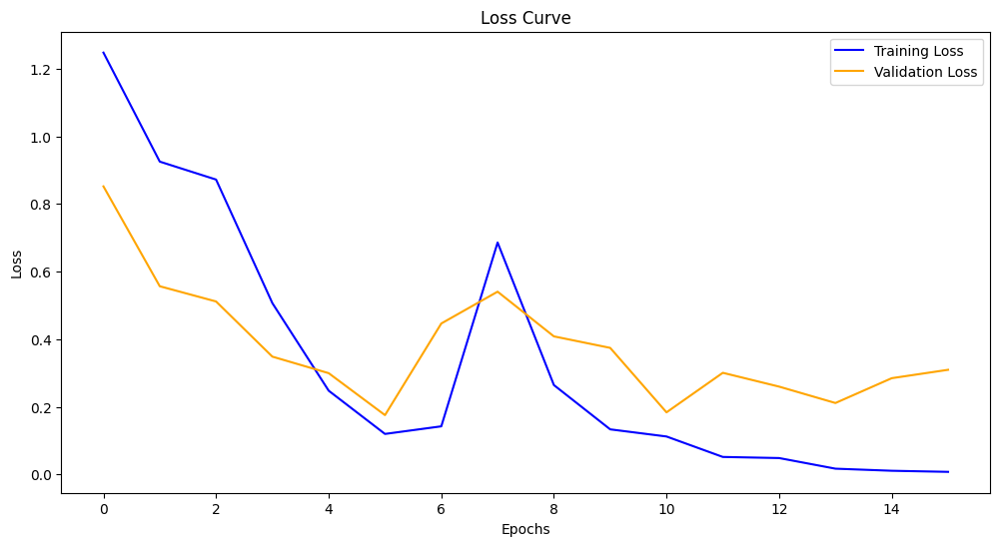

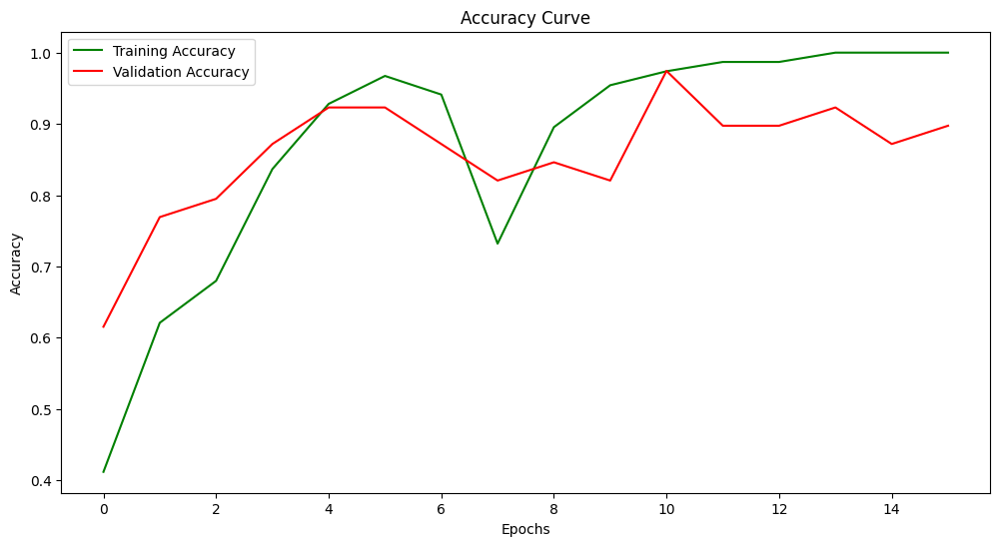

In [ ]:
import matplotlib.pyplot as plt

# Plot training and validation loss
def plot_training_history(training_history):
    # Plot loss
    plt.figure(figsize=(12, 6))
    plt.plot(training_history.history['loss'], label='Training Loss', color='blue')
    plt.plot(training_history.history['val_loss'], label='Validation Loss', color='orange')
    plt.title('Loss Curve')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()

    # Plot accuracy
    plt.figure(figsize=(12, 6))
    plt.plot(training_history.history['accuracy'], label='Training Accuracy', color='green')
    plt.plot(training_history.history['val_accuracy'], label='Validation Accuracy', color='red')
    plt.title('Accuracy Curve')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()

# Generate the plots
plot_training_history(convlstm_model_training_history)


In [ ]:
from collections import deque

def predict_on_video(video_path, model, sequence_length, image_height, image_width, class_names):
    frames_queue = deque(maxlen=sequence_length)
    video_reader = cv2.VideoCapture(video_path)
    prediction_frames = []

    while True:
        ret, frame = video_reader.read()
        if not ret:
            break

        resized_frame = cv2.resize(frame, (image_width, image_height))
        normalized_frame = resized_frame / 255.0
        frames_queue.append(normalized_frame)

        if len(frames_queue) == sequence_length:
            input_data = np.expand_dims(frames_queue, axis=0)
            predicted_probabilities = model.predict(input_data, verbose=0)[0]
            predicted_label = np.argmax(predicted_probabilities)
            predicted_class = class_names[predicted_label]

            # Annotate frame with prediction
            cv2.putText(frame, f"Action: {predicted_class}", (10, 30),
                        cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 2)
        prediction_frames.append(frame)

    video_reader.release()
    return prediction_frames


In [ ]:
def save_predicted_video(output_frames, output_path, fps):
    height, width, _ = output_frames[0].shape
    video_writer = cv2.VideoWriter(output_path, cv2.VideoWriter_fourcc(*'XVID'), fps, (width, height))

    for frame in output_frames:
        video_writer.write(frame)

    video_writer.release()
    print(f"Output video saved at {output_path}")

# Usage Example:
input_video_path = "/content/drive/MyDrive/UCF5/input_1.mp4"  # Replace with your test video path
output_video_path = "/content/drive/MyDrive/output_predicted_video.avi"
fps = 30  # Modify as per your video properties

predicted_frames = predict_on_video(input_video_path, convlstm_model, SEQUENCE_LENGTH, IMAGE_HEIGHT, IMAGE_WIDTH, CLASSES_LIST)
save_predicted_video(predicted_frames, output_video_path, fps)


Output video saved at /content/drive/MyDrive/output_predicted_video.avi


In [ ]:
from moviepy.editor import VideoFileClip

# Display video (adjust duration for longer videos)
output_clip = VideoFileClip(output_video_path)
output_clip.ipython_display(maxduration=1000)


/usr/local/lib/python3.12/dist-packages/moviepy/config_defaults.py:47: SyntaxWarning: invalid escape sequence '\P'
  IMAGEMAGICK_BINARY = r"C:\Program Files\ImageMagick-6.8.8-Q16\magick.exe"
/usr/local/lib/python3.12/dist-packages/moviepy/video/io/ffmpeg_reader.py:294: SyntaxWarning: invalid escape sequence '\d'
  lines_video = [l for l in lines if ' Video: ' in l and re.search('\d+x\d+', l)]
/usr/local/lib/python3.12/dist-packages/moviepy/video/io/ffmpeg_reader.py:367: SyntaxWarning: invalid escape sequence '\d'
  rotation_lines = [l for l in lines if 'rotate          :' in l and re.search('\d+$', l)]
/usr/local/lib/python3.12/dist-packages/moviepy/video/io/ffmpeg_reader.py:370: SyntaxWarning: invalid escape sequence '\d'
  match = re.search('\d+$', rotation_line)
  if event.key is 'enter':



Moviepy - Building video __temp__.mp4.
Moviepy - Writing video __temp__.mp4



Moviepy - Done !
Moviepy - video ready __temp__.mp4


In [ ]:
# Evaluate test performance
test_loss, test_accuracy = convlstm_model.evaluate(features_test, labels_test)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")


3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - accuracy: 0.8645 - loss: 0.4552
Test Loss: 0.5159
Test Accuracy: 0.8462


3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 96ms/step 


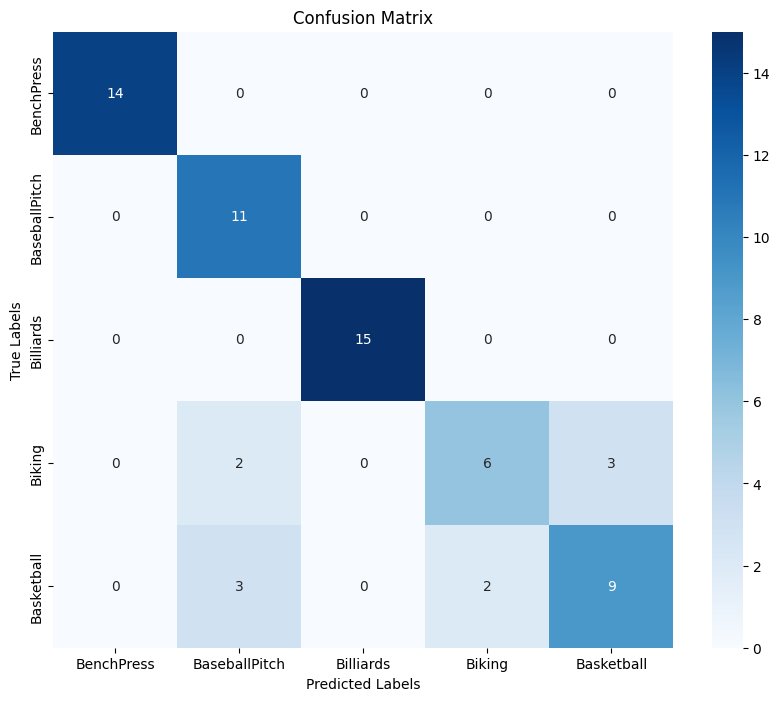

Classification Report:
                precision    recall  f1-score   support

   BenchPress       1.00      1.00      1.00        14
BaseballPitch       0.69      1.00      0.81        11
    Billiards       1.00      1.00      1.00        15
       Biking       0.75      0.55      0.63        11
   Basketball       0.75      0.64      0.69        14

     accuracy                           0.85        65
    macro avg       0.84      0.84      0.83        65
 weighted avg       0.85      0.85      0.84        65



In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Predictions on test data
y_pred = np.argmax(convlstm_model.predict(features_test), axis=1)
y_true = np.argmax(labels_test, axis=1)

# Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, cmap="Blues", xticklabels=CLASSES_LIST, yticklabels=CLASSES_LIST, fmt="d")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

# Classification Report
report = classification_report(y_true, y_pred, target_names=CLASSES_LIST)
print("Classification Report:\n", report)


3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 117ms/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step
Classification Report:
                precision    recall  f1-score   support

   BenchPress     1.0000    1.0000    1.0000        14
BaseballPitch     0.6875    1.0000    0.8148        11
    Billiards     1.0000    1.0000    1.0000        15
       Biking     0.7500    0.5455    0.6316        11
   Basketball     0.7500    0.6429    0.6923        14

     accuracy                         0.8462        65
    macro avg     0.8375    0.8377    0.8277        65
 weighted avg     0.8510    0.8462    0.8400        65



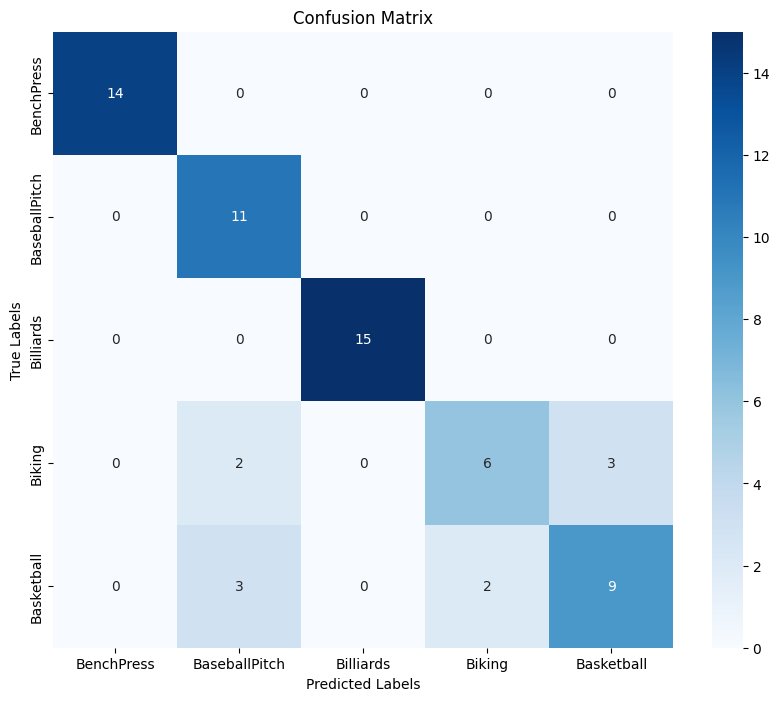

Cohen's Kappa Score: 0.8072
Matthews Correlation Coefficient (MCC): 0.8118
Log Loss: 0.5159
ROC-AUC Score: 0.9701
Hamming Loss: 0.1538
Jaccard Score: 0.7546
Top-3 Accuracy: 0.9846


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, cohen_kappa_score
from sklearn.metrics import matthews_corrcoef, log_loss, roc_auc_score, hamming_loss, jaccard_score
from tensorflow.keras.metrics import TopKCategoricalAccuracy
import seaborn as sns
import matplotlib.pyplot as plt

# Predictions
y_pred = np.argmax(convlstm_model.predict(features_test), axis=1)
y_true = np.argmax(labels_test, axis=1)
y_pred_prob = convlstm_model.predict(features_test)

# Classification Report
report = classification_report(y_true, y_pred, target_names=CLASSES_LIST, digits=4)
print("Classification Report:\n", report)

# Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, cmap="Blues", xticklabels=CLASSES_LIST, yticklabels=CLASSES_LIST, fmt="d")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

# Additional Metrics
kappa_score = cohen_kappa_score(y_true, y_pred)
mcc = matthews_corrcoef(y_true, y_pred)
logloss = log_loss(labels_test, y_pred_prob)
roc_auc = roc_auc_score(labels_test, y_pred_prob, multi_class="ovr")
hamming = hamming_loss(y_true, y_pred)
jaccard = jaccard_score(y_true, y_pred, average='weighted')

# Top-3 Accuracy
top_k_metric = TopKCategoricalAccuracy(k=3)
top_k_metric.update_state(labels_test, y_pred_prob)
top_k_accuracy = top_k_metric.result().numpy()

# Print Results
print(f"Cohen's Kappa Score: {kappa_score:.4f}")
print(f"Matthews Correlation Coefficient (MCC): {mcc:.4f}")
print(f"Log Loss: {logloss:.4f}")
print(f"ROC-AUC Score: {roc_auc:.4f}")
print(f"Hamming Loss: {hamming:.4f}")
print(f"Jaccard Score: {jaccard:.4f}")
print(f"Top-3 Accuracy: {top_k_accuracy:.4f}")


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


  super().__init__(**kwargs)



Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8619 - loss: 0.4893 - val_accuracy: 0.9574 - val_loss: 0.1478
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.9578 - loss: 0.1412 - val_accuracy: 0.9668 - val_loss: 0.1116
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9736 - loss: 0.0915 - val_accuracy: 0.9698 - val_loss: 0.1027
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9815 - loss: 0.0656 - val_accuracy: 0.9697 - val_loss: 0.0994
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9866 - loss: 0.0481 - val_accuracy: 0.9718 - val_loss: 0.0962
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9903 - loss: 0.0353 - val_accuracy: 0.9711 - val_loss: 0.0969
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9939 - loss: 0.0261 - val_accuracy: 0.9726 - val_loss: 0.0970
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9954 - loss: 0.0199 - 

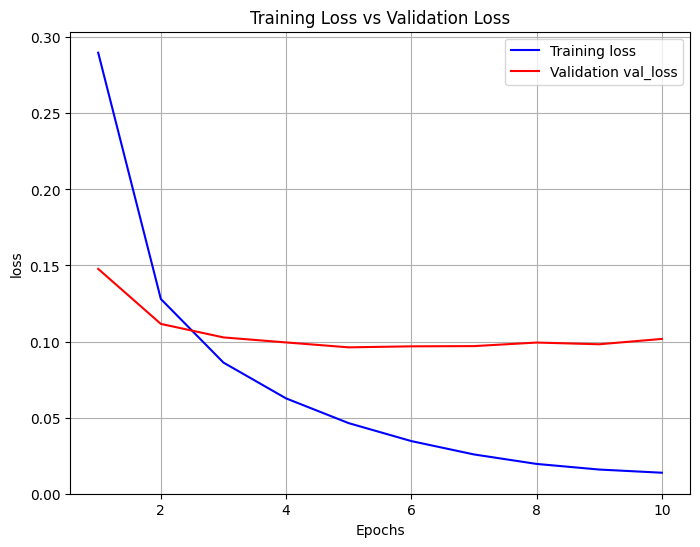

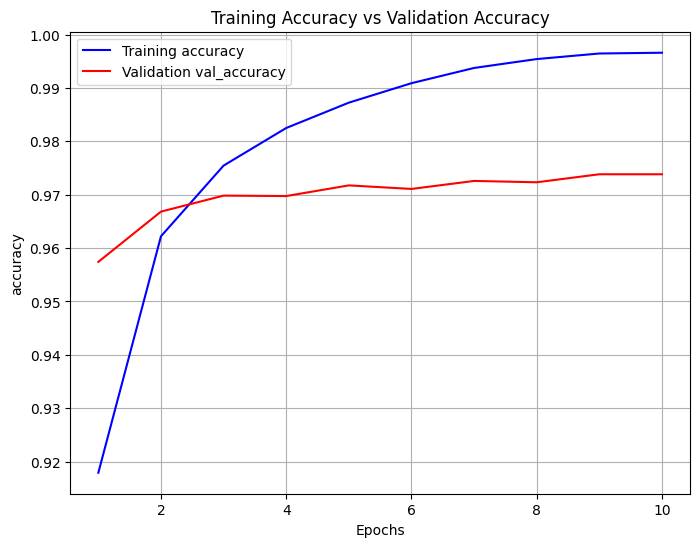

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [ ]:
# Import necessary libraries
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras.datasets import mnist

# Function to plot metrics
def plot_metrics(model_training_history, metric_name_1, metric_name_2, plot_name):
    """
    Plots training and validation metrics for comparison.

    Args:
    - model_training_history: The history object returned by the model's fit() method.
    - metric_name_1: Name of the training metric to plot (e.g., 'loss' or 'accuracy').
    - metric_name_2: Name of the validation metric to plot (e.g., 'val_loss' or 'val_accuracy').
    - plot_name: Title of the plot.

    Returns:
    - None
    """
    metric_value_1 = model_training_history.history[metric_name_1]
    metric_value_2 = model_training_history.history[metric_name_2]
    epochs = range(1, len(metric_value_1) + 1)

    plt.figure(figsize=(8, 6))
    plt.plot(epochs, metric_value_1, 'blue', label=f'Training {metric_name_1}')
    plt.plot(epochs, metric_value_2, 'red', label=f'Validation {metric_name_2}')
    plt.title(plot_name)
    plt.xlabel('Epochs')
    plt.ylabel(metric_name_1)
    plt.legend()
    plt.grid(True)
    plt.show()

# Load the MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0  # Normalize the data

# Build a simple neural network model
model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

# Compile the model
model.compile(optimizer=Adam(),
              loss=SparseCategoricalCrossentropy(),
              metrics=['accuracy'])

# Train the model and save the history
convistm_model_training_history = model.fit(x_train, y_train, validation_split=0.2, epochs=10)

# Evaluate the model on the test dataset
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=2)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# Plot metrics for training vs validation
plot_metrics(convistm_model_training_history, 'loss', 'val_loss', 'Training Loss vs Validation Loss')
plot_metrics(convistm_model_training_history, 'accuracy', 'val_accuracy', 'Training Accuracy vs Validation Accuracy')

# Predictions on test data (optional)
y_pred = model.predict(x_test)


In [ ]:
# WORKING WITH 5 CLASSES

In [ ]:
model.save("5_classes_model.h5")


In [ ]:
from google.colab import files
files.download("5_classes_model.h5")  # ✅ This downloads the file to your PC


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
model.save('model.h5')


In [ ]:
model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 305,312 (1.16 MB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 203,542 (795.09 KB)